# K-Means: so sánh nhánh không PCA và có PCA

## Mục tiêu

- Chạy K-Means trên dữ liệu gốc đã chuẩn bị, không dùng PCA.
- Chạy K-Means trên dữ liệu PCA; ưu tiên dùng file PhamGiaBao_pca_result.csv nếu có.
- So sánh số cụm bằng inertia và silhouette score trên mẫu đánh giá.
- Ghép nhãn cụm vào dữ liệu gốc và xuất data/LeDangKhoa_clustered.csv.

**Lưu ý về tệp hiện có:** ảnh nhắc tới data/PhamGiaBao_pca_result.csv, nhưng tệp được gửi tên PhamGiaBao_master_concat…csv và chỉ có 7 cột dữ liệu gốc. Nếu không tìm thấy file PCA, notebook tự chạy PCA trên cùng ma trận đặc trưng của EDA để hai nhánh dùng cùng giao dịch, giúp so sánh công bằng hơn.

## 0. Thư viện và cấu hình

Nếu môi trường thiếu thư viện, cài bằng lệnh: pip install pandas numpy scipy scikit-learn matplotlib.

K-Means nhạy với thang đo, vì vậy các cột số được chuẩn hóa. Cột phân loại được One-Hot Encode. Để chạy nhanh trên dữ liệu lớn, notebook chọn K trên một mẫu ngẫu nhiên có seed cố định; mô hình cuối sau đó được fit trên toàn bộ dữ liệu.

In [2]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import IncrementalPCA, PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from IPython.display import display
except ImportError:
    display = print

RANDOM_STATE = 42
K_VALUES = range(2, 9)
SELECTION_SAMPLE_SIZE = 8000
SILHOUETTE_SAMPLE_SIZE = 1500
FINAL_SILHOUETTE_SAMPLE_SIZE = 2000

## 1. Đọc các file và xác nhận đúng loại dữ liệu

File EDA là dữ liệu đầu vào cho nhánh không PCA. File master được đọc để kiểm tra nguồn dữ liệu, nhưng không được xem là file PCA. File PCA riêng sẽ được nạp nếu có trong data, thư mục hiện tại hoặc attached_assets.

In [3]:
from pathlib import Path
import pandas as pd

# Đọc 2 file
df1 = pd.read_csv("NguyenTheHoang_final_eda.csv", low_memory=False)
df2 = pd.read_csv("PhamGiaBao_pca_result.csv", low_memory=False)

# Xóa cột Transaction ID ở df2 (nếu có) để tránh bị trùng lặp cột khi ghép ngang
if "Transaction ID" in df2.columns:
  df2 = df2.drop(columns=["Transaction ID"])

# Ghép ngang an toàn không bị trùng cột
df_original = pd.concat([df1, df2], axis=1)

print("Kích thước sau khi ghép:", df_original.shape)
display(df_original.head())

Kích thước sau khi ghép: (158656, 17)


,Transaction ID,Transaction Date,Product Name,Quantity,Price,Store Location,Source,Sales Amount,Month,Weekday,Price Range,Source_Cafe Sales,Source_Coffee Shop Sales,Sales Amount (scaled),PC1,PC2,PC3
0,TXN_1961373,2023-09-08,Coffee,2.0,2.0,Takeaway,Cafe Sales,4.0,9,Friday,Low,True,False,-0.211372,2.697193,-3.003622,1.631254
1,TXN_4977031,2023-05-16,Cake,4.0,3.0,In-store,Cafe Sales,12.0,5,Tuesday,Medium,True,False,1.583948,4.701360,-2.110462,-1.444089
2,TXN_4271903,2023-07-19,Cookie,4.0,1.0,In-store,Cafe Sales,4.0,7,Wednesday,Low,True,False,-0.211372,3.754651,-3.735655,-0.572581
3,TXN_7034554,2023-04-27,Salad,2.0,5.0,Takeaway,Cafe Sales,10.0,4,Thursday,Medium,True,False,1.135118,3.065576,-0.799550,-0.424530
4,TXN_3160411,2023-06-11,Coffee,2.0,2.0,In-store,Cafe Sales,4.0,6,Sunday,Low,True,False,-0.211372,2.262689,-2.501309,0.304358


In [4]:
print("Danh sách cột EDA:")
print(df_original.columns.tolist())
print("\nKích thước:", df_original.shape)
print("\nGiá trị thiếu:")
display(df_original.isna().sum().sort_values(ascending=False))

if "Transaction ID" in df_original.columns:
    duplicate_ids = int(df_original["Transaction ID"].duplicated().sum())
    print("Mã giao dịch trùng:", duplicate_ids)

print("\nThống kê mô tả các cột số:")
display(df_original.describe(include="number").T)

Danh sách cột EDA:
['Transaction ID', 'Transaction Date', 'Product Name', 'Quantity', 'Price', 'Store Location', 'Source', 'Sales Amount', 'Month', 'Weekday', 'Price Range', 'Source_Cafe Sales', 'Source_Coffee Shop Sales', 'Sales Amount (scaled)', 'PC1', 'PC2', 'PC3']

Kích thước: (158656, 17)

Giá trị thiếu:


Transaction ID              0
Transaction Date            0
Product Name                0
Quantity                    0
Price                       0
Store Location              0
Source                      0
Sales Amount                0
Month                       0
Weekday                     0
Price Range                 0
Source_Cafe Sales           0
Source_Coffee Shop Sales    0
Sales Amount (scaled)       0
PC1                         0
PC2                         0
PC3                         0
dtype: int64

Mã giao dịch trùng: 0

Thống kê mô tả các cột số:


,count,mean,std,min,25%,50%,75%,max
Quantity,158656.0,1.533633e+00,0.730713,1.000000,1.000000,1.000000,2.000000,8.000000
Price,158656.0,3.356391e+00,2.597527,0.800000,2.500000,3.000000,3.750000,45.000000
Sales Amount,158656.0,4.941879e+00,4.456045,0.800000,3.000000,4.000000,6.000000,360.000000
Month,158656.0,4.141318e+00,1.926012,1.000000,3.000000,4.000000,6.000000,12.000000
Sales Amount (scaled),158656.0,-2.006373e-16,1.000003,-0.929500,-0.435787,-0.211372,0.237458,79.680359
PC1,158656.0,3.152872e-17,1.408901,-1.774510,-0.791960,-0.364916,0.399034,54.539309
PC2,158656.0,-5.732495e-18,1.211034,-4.878483,-0.303022,-0.006387,0.328488,42.764650
PC3,158656.0,-9.171992e-17,0.943801,-9.334562,-0.637424,0.044008,0.685743,4.297780


## 2. Chọn đặc trưng cho K-Means

Dùng Quantity, Price, Month và các biến phân loại Product Name, Store Location, Source, Weekday. Bỏ Transaction ID và Transaction Date vì chúng không đại diện trực tiếp cho hành vi giao dịch trong cấu hình này.

Không đưa Sales Amount, Sales Amount (scaled) và Price Range vào cùng lúc với Price và Quantity: Sales Amount được tính từ Quantity × Price, còn Price Range được suy ra từ Price. Giữ các bản sao dẫn xuất có thể làm một khía cạnh bị tính trọng số nhiều lần trong khoảng cách Euclidean.

In [5]:
NUMERIC_FEATURES = ["Quantity", "Price", "Month"]
CATEGORICAL_FEATURES = ["Product Name", "Store Location", "Source", "Weekday"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

missing_features = [column for column in FEATURES if column not in df_original.columns]
if missing_features:
    raise ValueError(f"Thiếu cột đặc trưng: {missing_features}")
if df_original["Transaction ID"].isna().any():
    df_model = df_original.loc[df_original["Transaction ID"].notna()].reset_index(drop=True)
else:
    df_model = df_original
X_raw = df_model[FEATURES]

print("Số giao dịch dùng để phân cụm:", len(X_raw))
print("Số đặc trưng trước mã hóa:", len(FEATURES))
print("Đặc trưng số:", NUMERIC_FEATURES)
print("Đặc trưng phân loại:", CATEGORICAL_FEATURES)

Số giao dịch dùng để phân cụm: 158656
Số đặc trưng trước mã hóa: 7
Đặc trưng số: ['Quantity', 'Price', 'Month']
Đặc trưng phân loại: ['Product Name', 'Store Location', 'Source', 'Weekday']


## 3. Tiền xử lý dữ liệu gốc

Đặc trưng số được điền median và chuẩn hóa bằng StandardScaler. Đặc trưng phân loại được điền giá trị phổ biến nhất và mã hóa One-Hot. Đây là ma trận đầu vào của nhánh K-Means không PCA.

In [6]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ],
    remainder="drop",
)
X_no_pca = preprocessor.fit_transform(X_raw)
del X_raw
print("Kích thước ma trận không PCA:", X_no_pca.shape)
print("Định dạng ma trận:", "sparse" if sparse.issparse(X_no_pca) else "dense")

Kích thước ma trận không PCA: (158656, 105)
Định dạng ma trận: sparse


## 4. Chọn K cho nhánh không PCA

Thử K từ 2 đến 8 trên một mẫu ngẫu nhiên có seed cố định. Inertia càng thấp càng tốt nhưng thường giảm khi K tăng; silhouette score càng cao càng tốt. Silhouette được tính trên một mẫu con để giảm thời gian chạy, nên đây là ước lượng chứ không phải điểm trên toàn bộ tập.

In [7]:
def evaluate_k_values(X, k_values=K_VALUES, random_state=RANDOM_STATE):
    n_rows = X.shape[0]
    sample_size = min(SELECTION_SAMPLE_SIZE, n_rows)
    rng = np.random.default_rng(random_state)
    sample_indices = rng.choice(n_rows, size=sample_size, replace=False)
    X_sample = X[sample_indices]
    rows = []
    silhouette_n = min(SILHOUETTE_SAMPLE_SIZE, sample_size)
    for k in k_values:
        model = KMeans(
            n_clusters=k,
            n_init=3,
            max_iter=100,
            random_state=random_state,
            algorithm="lloyd",
        )
        labels = model.fit_predict(X_sample)
        score = silhouette_score(
            X_sample,
            labels,
            sample_size=silhouette_n,
            random_state=random_state,
        )
        rows.append({"K": k, "Inertia": model.inertia_, "Silhouette (sample)": score})
    return pd.DataFrame(rows)
results_no_pca = evaluate_k_values(X_no_pca)
display(results_no_pca.round(4))
best_k_no_pca = int(
    results_no_pca.loc[results_no_pca["Silhouette (sample)"].idxmax(), "K"]
)
print("K được chọn cho nhánh không PCA:", best_k_no_pca)


,K,Inertia,Silhouette (sample)
0,2,39038.1735,0.1306
1,3,34794.7346,0.1283
2,4,30204.8948,0.1472
3,5,28720.4587,0.1131
4,6,26322.9010,0.1244
5,7,25580.6855,0.1163
6,8,24758.8902,0.1150


K được chọn cho nhánh không PCA: 4


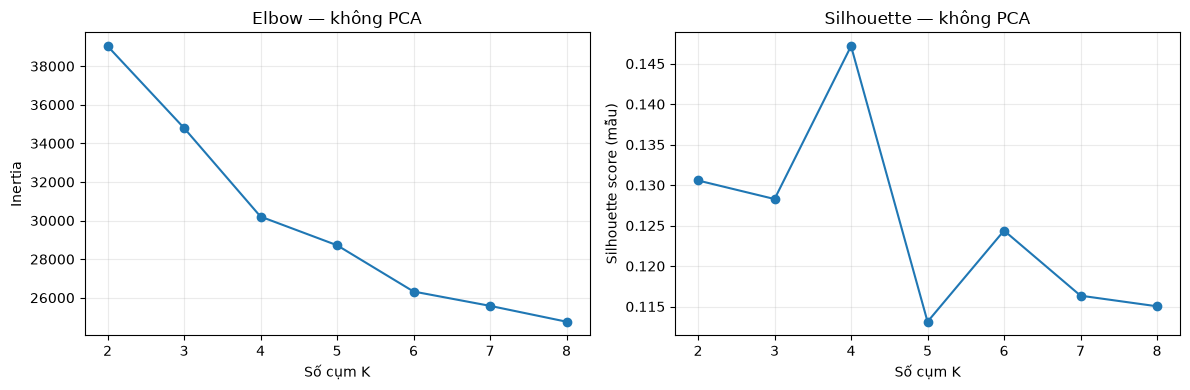

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(results_no_pca["K"], results_no_pca["Inertia"], marker="o")
axes[0].set_title("Elbow — không PCA")
axes[0].set_xlabel("Số cụm K")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.25)

axes[1].plot(results_no_pca["K"], results_no_pca["Silhouette (sample)"], marker="o")
axes[1].set_title("Silhouette — không PCA")
axes[1].set_xlabel("Số cụm K")
axes[1].set_ylabel("Silhouette score (mẫu)")
axes[1].grid(alpha=0.25)

fig.tight_layout()
plt.show()

## 5. Chuẩn bị dữ liệu cho nhánh PCA

Nếu tìm thấy file PCA riêng, notebook lấy các cột thành phần PC/PCA và ghép theo Transaction ID để giữ đúng thứ tự giao dịch. Nếu file không có ID, chỉ chấp nhận khi số dòng khớp và ghi cảnh báo về giả định thứ tự.

Nếu file PCA không có sẵn, notebook ước lượng số thành phần cần thiết trên một mẫu nhỏ rồi dùng IncrementalPCA theo từng lô trên cùng ma trận EDA. Cách này giảm mức dùng RAM và hướng tới giữ 95% phương sai; tỷ lệ thực tế sẽ được in ra.

In [9]:
from pathlib import Path
import re
import warnings

PCA_COMPONENT_PATTERN = re.compile(r"(?:PC|PCA|PRINCIPAL_COMPONENT)[_\s-]*\d+", flags=re.IGNORECASE)
PCA_RESULT_PATH = Path("PhamGiaBao_pca_result.csv")

if PCA_RESULT_PATH.exists():
    pca_df = pd.read_csv(PCA_RESULT_PATH, low_memory=False)
    component_columns = [
        column for column in pca_df.columns
        if PCA_COMPONENT_PATTERN.fullmatch(str(column))
    ]
    component_columns = sorted(
        component_columns,
        key=lambda column: int(re.search(r"\d+$", str(column)).group()),
    )
    if not component_columns:
        raise ValueError(
            "File PCA được tìm thấy nhưng không có cột thành phần dạng PC1/PC_1/PCA1. "
            "Kiểm tra lại tên cột trong PCA_RESULT_PATH."
        )

    if "Transaction ID" in pca_df.columns:
        pca_df["Transaction ID"] = pca_df["Transaction ID"].astype(str)
        eda_ids = df_model["Transaction ID"].astype(str)
        if pca_df["Transaction ID"].duplicated().any():
            raise ValueError("Transaction ID bị trùng trong file PCA.")
        pca_ids = set(pca_df["Transaction ID"])
        missing_ids = set(eda_ids) - pca_ids
        if missing_ids:
            raise ValueError(
                f"File PCA thiếu {len(missing_ids):,} Transaction ID của file EDA; "
                "không thể gán nhãn theo đúng dòng."
            )
        pca_df = pca_df.set_index("Transaction ID").loc[eda_ids].reset_index()
        print("Đã căn hàng PCA theo Transaction ID.")
    elif len(pca_df) == len(df_model):
        warnings.warn(
            "File PCA không có Transaction ID; giả định thứ tự dòng trùng với file EDA.",
            UserWarning,
        )
    else:
        raise ValueError(
            "File PCA không có Transaction ID và số dòng không khớp file EDA. "
            "Không thể ghép nhãn an toàn."
        )

    X_pca = pca_df[component_columns].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float32)
    if not np.isfinite(X_pca).all():
        raise ValueError("Các cột PCA chứa giá trị thiếu hoặc không hữu hạn.")
    PCA_SOURCE = str(PCA_RESULT_PATH)
    pca_model = None
    print("Nguồn nhánh PCA:", PCA_SOURCE)
    print("Các thành phần được dùng:", component_columns)
else:
    n_rows, n_features = X_no_pca.shape
    pilot_size = min(20000, n_rows)
    rng = np.random.default_rng(RANDOM_STATE)
    pilot_indices = rng.choice(n_rows, size=pilot_size, replace=False)
    pilot_sparse = X_no_pca[pilot_indices]
    pilot_dense = pilot_sparse.toarray() if sparse.issparse(pilot_sparse) else np.asarray(pilot_sparse)

    pilot_components = min(pilot_size, n_features)
    pilot_pca = PCA(n_components=pilot_components, svd_solver="full", random_state=RANDOM_STATE)
    pilot_pca.fit(pilot_dense)
    cumulative_variance = np.cumsum(pilot_pca.explained_variance_ratio_)
    selected_components = int(np.searchsorted(cumulative_variance, 0.95) + 1)
    selected_components = min(n_features, max(2, selected_components + 2))
    del pilot_sparse, pilot_dense, pilot_pca, cumulative_variance, pilot_indices

    pca_model = IncrementalPCA(
        n_components=selected_components,
        batch_size=min(4096, n_rows),
    )
    batch_size = min(4096, n_rows)
    batch_ranges = [(start, min(start + batch_size, n_rows)) for start in range(0, n_rows, batch_size)]
    if len(batch_ranges) > 1 and batch_ranges[-1][1] - batch_ranges[-1][0] < selected_components:
        previous_start = batch_ranges[-2][0]
        batch_ranges[-2] = (previous_start, n_rows)
        batch_ranges.pop()

    for start, end in batch_ranges:
        batch = X_no_pca[start:end]
        batch_dense = batch.toarray() if sparse.issparse(batch) else np.asarray(batch)
        pca_model.partial_fit(batch_dense)

    X_pca = np.empty((n_rows, selected_components), dtype=np.float32)
    for start, end in batch_ranges:
        batch = X_no_pca[start:end]
        batch_dense = batch.toarray() if sparse.issparse(batch) else np.asarray(batch)
        X_pca[start:end] = pca_model.transform(batch_dense).astype(np.float32)

    PCA_SOURCE = "IncrementalPCA tạo từ ma trận đặc trưng EDA"
    print("Nguồn nhánh PCA:", PCA_SOURCE)
    print("Số thành phần giữ lại:", pca_model.n_components_)
    print("Tỷ lệ phương sai giải thích trên toàn bộ dữ liệu:", round(float(pca_model.explained_variance_ratio_.sum()), 4))

print("Kích thước ma trận PCA:", X_pca.shape)

Đã căn hàng PCA theo Transaction ID.
Nguồn nhánh PCA: PhamGiaBao_pca_result.csv
Các thành phần được dùng: ['PC1', 'PC2', 'PC3']
Kích thước ma trận PCA: (158656, 3)


## 6. Chọn K cho nhánh có PCA

Dùng cùng khoảng K, cách lấy mẫu và seed như nhánh không PCA. Inertia của hai không gian đặc trưng không nên so trực tiếp vì PCA thay đổi số chiều và thang khoảng cách; silhouette là chỉ số thuận tiện hơn để so sánh độ tách cụm, nhưng vẫn là ước lượng trên mẫu.

In [10]:
results_pca = evaluate_k_values(X_pca)
display(results_pca.round(4))
best_k_pca = int(
    results_pca.loc[results_pca["Silhouette (sample)"].idxmax(), "K"]
)
print("K được chọn cho nhánh PCA:", best_k_pca)


,K,Inertia,Silhouette (sample)
0,2,25390.3125,0.6982
1,3,21350.6992,0.3372
2,4,15202.8789,0.3715
3,5,10984.6768,0.3603
4,6,9717.1680,0.3566
5,7,7728.1528,0.4013
6,8,6488.5063,0.4385


K được chọn cho nhánh PCA: 2


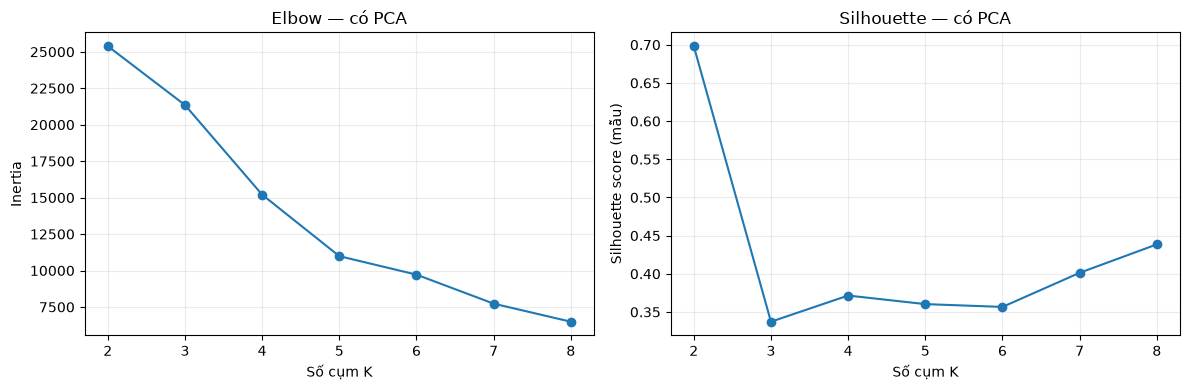

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(results_pca["K"], results_pca["Inertia"], marker="o")
axes[0].set_title("Elbow — có PCA")
axes[0].set_xlabel("Số cụm K")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.25)

axes[1].plot(results_pca["K"], results_pca["Silhouette (sample)"], marker="o")
axes[1].set_title("Silhouette — có PCA")
axes[1].set_xlabel("Số cụm K")
axes[1].set_ylabel("Silhouette score (mẫu)")
axes[1].grid(alpha=0.25)

fig.tight_layout()
plt.show()

## 7. Huấn luyện K-Means cuối cùng trên toàn bộ giao dịch

K được chọn riêng cho từng nhánh theo silhouette score cao nhất trong khoảng đã thử. Hai mô hình được fit trên toàn bộ dòng EDA. Nhãn cụm là số hiệu kỹ thuật; Cluster 0 không có nghĩa tốt hơn Cluster 1.

In [12]:
final_no_pca = KMeans(
    n_clusters=best_k_no_pca,
    n_init=5,
    max_iter=100,
    random_state=RANDOM_STATE,
    algorithm="lloyd",
)
labels_no_pca = final_no_pca.fit_predict(X_no_pca)

final_pca = KMeans(
    n_clusters=best_k_pca,
    n_init=5,
    max_iter=100,
    random_state=RANDOM_STATE,
    algorithm="lloyd",
)
labels_pca = final_pca.fit_predict(X_pca)

silhouette_no_pca = silhouette_score(
    X_no_pca,
    labels_no_pca,
    sample_size=min(FINAL_SILHOUETTE_SAMPLE_SIZE, len(labels_no_pca)),
    random_state=RANDOM_STATE,
)
silhouette_pca = silhouette_score(
    X_pca,
    labels_pca,
    sample_size=min(FINAL_SILHOUETTE_SAMPLE_SIZE, len(labels_pca)),
    random_state=RANDOM_STATE,
)

comparison = pd.DataFrame(
    [
        {"Phương pháp": "K-Means không PCA", "K": best_k_no_pca,
         "Silhouette (mẫu cuối)": silhouette_no_pca,
         "Số dòng": len(labels_no_pca)},
        {"Phương pháp": "K-Means có PCA", "K": best_k_pca,
         "Silhouette (mẫu cuối)": silhouette_pca,
         "Số dòng": len(labels_pca)},
    ]
)
display(comparison.round(4))


,Phương pháp,K,Silhouette (mẫu cuối),Số dòng
0,K-Means không PCA,4,0.1344,158656
1,K-Means có PCA,2,0.6736,158656


## 8. Xem quy mô và đặc trưng các cụm

Xem số giao dịch mỗi cụm ở cả hai nhánh. Bảng hồ sơ bên dưới mô tả các cụm không PCA trên những trường gốc; đây là thống kê mô tả, không phải quan hệ nhân quả.

In [13]:
labels_no_pca_series = pd.Series(labels_no_pca, index=df_model.index, name="Cluster_Label")
labels_pca_series = pd.Series(labels_pca, index=df_model.index, name="Cluster_Label_PCA")
print("Số giao dịch theo cụm — không PCA:")
display(labels_no_pca_series.value_counts().sort_index().rename("Transactions").to_frame())
print("Số giao dịch theo cụm — PCA:")
display(labels_pca_series.value_counts().sort_index().rename("Transactions").to_frame())
profile_columns = [column for column in ["Quantity", "Price", "Sales Amount"] if column in df_model.columns]
profile_data = df_model[profile_columns].copy()
profile_data["Transaction ID"] = df_model["Transaction ID"]
profile_data["Cluster_Label"] = labels_no_pca
cluster_profile = (
    profile_data.groupby("Cluster_Label")
    .agg(
        Transactions=("Transaction ID", "size"),
        **{f"Mean {column}": (column, "mean") for column in profile_columns},
    )
    .round(3)
)
display(cluster_profile)

Số giao dịch theo cụm — không PCA:


,Transactions
Cluster_Label,
0,65206
1,82283
2,8657
3,2510


Số giao dịch theo cụm — PCA:


,Transactions
Cluster_Label_PCA,
0,8749
1,149907


,Transactions,Mean Quantity,Mean Price,Mean Sales Amount
Cluster_Label,,,,
0,65206,1.535,3.069,4.637
1,82283,1.335,3.115,4.097
2,8657,3.550,2.931,10.451
3,2510,1.034,20.185,21.535


## 9. Xuất dữ liệu gốc kèm nhãn cụm

Theo ảnh, cột Cluster_Label lưu nhãn từ nhánh K-Means không PCA. Notebook thêm Cluster_Label_PCA để đối chiếu trực tiếp nhãn PCA trên cùng Transaction ID; nếu cần đúng một cột nhãn duy nhất, có thể xóa dòng gán Cluster_Label_PCA trước khi lưu.

In [ ]:
OUTPUT_PATH = Path("data/LeDangKhoa_clustered.csv")
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
clustered_output = df_model.copy()
clustered_output["Cluster_Label"] = labels_no_pca
clustered_output["Cluster_Label_PCA"] = labels_pca
pca_export_columns = [column for column in ["PC1", "PC2", "PC3"] if column in clustered_output.columns]
if pca_export_columns:
    clustered_output[pca_export_columns] = clustered_output[pca_export_columns].round(2)
clustered_output.to_csv(OUTPUT_PATH, index=False, encoding="utf-8-sig")
size_bytes = OUTPUT_PATH.stat().st_size
print("Đã lưu:", OUTPUT_PATH.resolve())
print("Kích thước bảng:", clustered_output.shape)
print(f"Dung lượng CSV: {size_bytes / 1_000_000:.2f} MB ({size_bytes / 1024**2:.2f} MiB)")
print("PC1–PC3 trong file đã làm tròn 2 chữ số; nhãn được tính từ dữ liệu PCA đầy đủ.")
print("Các cột nhãn:", ["Cluster_Label", "Cluster_Label_PCA"])
check_output = pd.read_csv(OUTPUT_PATH, low_memory=False)
assert len(check_output) == len(df_model)
assert check_output.shape[1] == len(df_model.columns) + 2
assert check_output["Cluster_Label"].notna().all()
assert check_output["Cluster_Label_PCA"].notna().all()
print("Kiểm tra file đầu ra: thành công.")


Đã lưu: C:\Users\USER\Downloads\dk\data\LeDangKhoa_clustered.csv
Kích thước bảng: (158656, 19)
Dung lượng CSV: 23.26 MB (22.18 MiB)
PC1–PC3 trong file đã làm tròn 2 chữ số; nhãn được tính từ dữ liệu PCA đầy đủ.
Các cột nhãn: ['Cluster_Label', 'Cluster_Label_PCA']
Kiểm tra file đầu ra: thành công.


## 10. Kết luận và lưu ý

Notebook chạy hai nhánh trên cùng tập giao dịch: K-Means trực tiếp trên đặc trưng đã mã hóa/chuẩn hóa và K-Means trên các thành phần PCA. K được chọn theo silhouette score lớn nhất trong khoảng K=2–8 trên mẫu đánh giá; cần xem thêm đường elbow và hồ sơ cụm trước khi chốt cách diễn giải.

File data/LeDangKhoa_clustered.csv giữ các cột gốc và thêm Cluster_Label cho nhánh không PCA cùng Cluster_Label_PCA để so sánh. Nếu có file PhamGiaBao_pca_result.csv, notebook căn chỉnh theo Transaction ID; nếu không, nó tự tạo PCA từ file EDA. File PhamGiaBao_master_concat…csv hiện là dữ liệu gốc, không phải dữ liệu PCA.